# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd

# Chargement du fichier brut
brut = pd.read_csv("donnees/consommation_brut.csv")

print(f"Forme du DataFrame : {brut.shape}\n")

print("Résumé des colonnes (Type / Valeurs manquantes) :")
summary = pd.DataFrame({
    'Type': brut.dtypes.astype(str),
    'Manquants': brut.isna().sum()
})
print(summary)

print(f"\nNombre de lignes en double : {brut.duplicated().sum()}")

Forme du DataFrame : (300, 4)

Résumé des colonnes (Type / Valeurs manquantes) :
                   Type  Manquants
mois                str          0
quartier            str          0
kwh                 str          9
heures_courant  float64          0

Nombre de lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print("\n--- QUESTION 2 ---")
print(f"Nombre d'écritures différentes dans la colonne 'quartier' : {len(brut['quartier'].unique())}")


--- QUESTION 2 ---
Nombre d'écritures différentes dans la colonne 'quartier' : 43


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
print("\n--- QUESTION 3 ---")
mask = pd.to_numeric(brut['kwh'], errors='coerce').isna() & brut['kwh'].notna()
print("Exemples de valeurs textuelles non numériques dans 'kwh' :")
print(brut.loc[mask, 'kwh'].unique())


--- QUESTION 3 ---
Exemples de valeurs textuelles non numériques dans 'kwh' :
<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh',
 '299610 kWh',    '373 880', '333670 kWh', '597730 kWh', '456060 kWh',
 '495020 kWh',    '409 300',    '556 070', '260360 kWh', '347870 kWh',
    '408 780',    '364 090', '243160 kWh',    '154 720',    '233 700',
    '253 300', '385840 kWh', '445270 kWh',    '337 810',    '366 390',
    '154 740', '170420 kWh', '201690 kWh',  '81370 kWh', '139470 kWh',
  '77670 kWh', '139230 kWh',    '121 240', '160110 kWh',    '105 830',
 '163010 kWh', '198720 kWh',    '281 240',    '104 640', '166700 kWh',
     '73 110',    '171 160', '187230 kWh']
Length: 48, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.assign(
    kwh=lambda df: pd.to_numeric(
        df['kwh'].astype(str).str.replace(r'(?i)kwh|\s+', '', regex=True), 
        errors='coerce'
    )
)
print(propre['kwh'].isna().sum())

9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers_ref = pd.read_csv("donnees/quartiers.csv")
mapping = dict(zip(quartiers_ref['quartier'].str.lower(), quartiers_ref['quartier']))

propre['quartier'] = propre['quartier'].astype(str).str.strip().str.lower().map(mapping)

print("Nombre de quartiers uniques après harmonisation :", propre['quartier'].nunique())
print("Nombre de valeurs manquantes (non trouvées par map) :", propre['quartier'].isna().sum())

Nombre de quartiers uniques après harmonisation : 12
Nombre de valeurs manquantes (non trouvées par map) : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.dropna(subset=['kwh']).drop_duplicates().reset_index(drop=True)
print(propre.shape)

(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane = propre.groupby('quartier')['kwh'].transform('median')
propre.loc[propre['kwh'] > 3 * mediane, 'kwh'] /= 10
print("Maximum de kwh après correction :", propre['kwh'].max())

Maximum de kwh après correction : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
ref = pd.read_csv("donnees/consommation.csv")
colonnes = propre.columns.tolist()

idx_propre = set(zip(propre['mois'], propre['quartier']))
ref_filtre = ref[ref.set_index(['mois', 'quartier']).index.isin(idx_propre)][colonnes]

propre_trie = propre[colonnes].sort_values(['mois', 'quartier']).reset_index(drop=True)
ref_trie = ref_filtre.sort_values(['mois', 'quartier']).reset_index(drop=True)

propre_trie['kwh'] = propre_trie['kwh'].astype(int)

propre_trie.equals(ref_trie)

True

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
print(f"Lignes avant jointure quartiers : {len(propre)}")
df_merge = propre.merge(quartiers_ref, on='quartier', how='left')
print(f"Lignes après jointure quartiers : {len(df_merge)}")

df_merge = df_merge.assign(
    kwh_par_abonne=(df_merge['kwh'] / df_merge['abonnes']).round(1),
    annee=pd.to_datetime(df_merge['mois']).dt.year
)

meteo = pd.read_csv("donnees/meteo.csv")
print(f"Lignes avant jointure météo : {len(df_merge)}")
df_propre_final = df_merge.merge(meteo, on=['mois', 'commune'], how='left')
print(f"Lignes après jointure météo : {len(df_propre_final)}")

df_propre_final.to_csv("donnees/consommation_propre.csv", index=False)
print("Fichier 'donnees/consommation_propre.csv' généré et sauvegardé avec succès !")

Lignes avant jointure quartiers : 279
Lignes après jointure quartiers : 279
Lignes avant jointure météo : 279
Lignes après jointure météo : 279
Fichier 'donnees/consommation_propre.csv' généré et sauvegardé avec succès !


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
print(f"Lignes avant jointure : {len(df_merge)}")
df_propre = df_merge.merge(meteo, on=['mois', 'commune'], how='left')
print(f"Lignes après jointure : {len(df_propre)}")
print(f"Températures manquantes : {df_propre['temperature_c'].isna().sum()}")

Lignes avant jointure : 279
Lignes après jointure : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
df_propre.to_csv("donnees/consommation_propre.csv", index=False)
print(pd.read_csv("donnees/consommation_propre.csv").shape)

(279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
conso_type = df_propre.groupby('type')['kwh_par_abonne'].mean()
print("Consommation moyenne par abonné selon le type de quartier :")
print(conso_type.round(1))

conso_quartier = (df_propre.groupby('quartier')['kwh'].sum() / df_propre.groupby('quartier')['abonnes'].sum()).sort_values(ascending=False)
print("\nClassement des 12 quartiers par consommation moyenne par abonné :")
print(conso_quartier.round(1))

Consommation moyenne par abonné selon le type de quartier :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des 12 quartiers par consommation moyenne par abonné :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.5
dtype: float64


**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee            2024   2025  Hausse (%)
commune                                 
Cap-Haïtien      4.59   5.62       22.46
Delmas          11.61  11.74        1.10
Port-au-Prince  10.09  10.31        2.27
Pétion-Ville     8.60   9.68       12.56


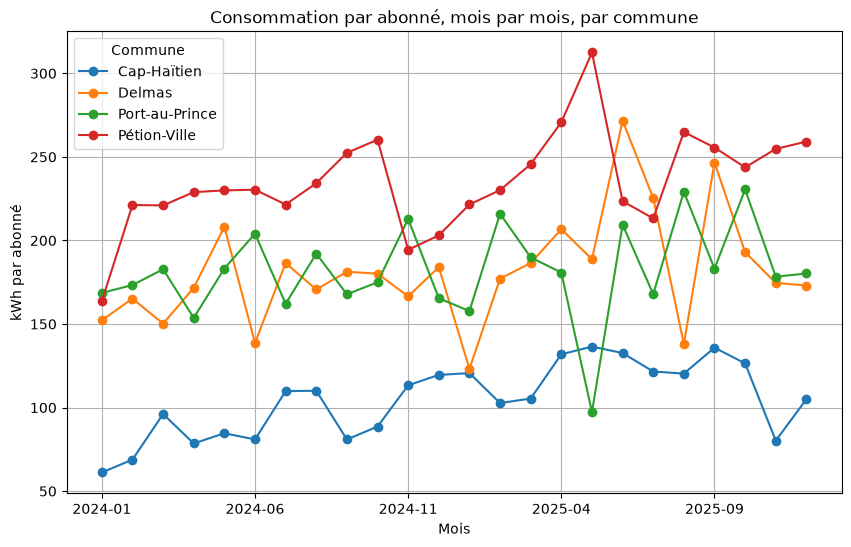

In [13]:
df_propre['annee'] = df_propre['mois'].astype(str).str[:4]
pivot_conso = df_propre.pivot_table(index='commune', columns='annee', values='kwh', aggfunc='sum').div(1e6)

annees = sorted(pivot_conso.columns)
pivot_conso['Hausse (%)'] = ((pivot_conso[annees[-1]] - pivot_conso[annees[0]]) / pivot_conso[annees[0]]).mul(100)

print(pivot_conso.round(2))

import matplotlib.pyplot as plt

conso_mensuelle = df_propre.groupby(['mois', 'commune']).apply(lambda g: g['kwh'].sum() / g['abonnes'].sum()).unstack()
conso_mensuelle.plot(figsize=(10, 6), marker='o')
plt.title("Consommation par abonné, mois par mois, par commune")
plt.xlabel("Mois")
plt.ylabel("kWh par abonné")
plt.legend(title="Commune")
plt.grid(True)
plt.show()

**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

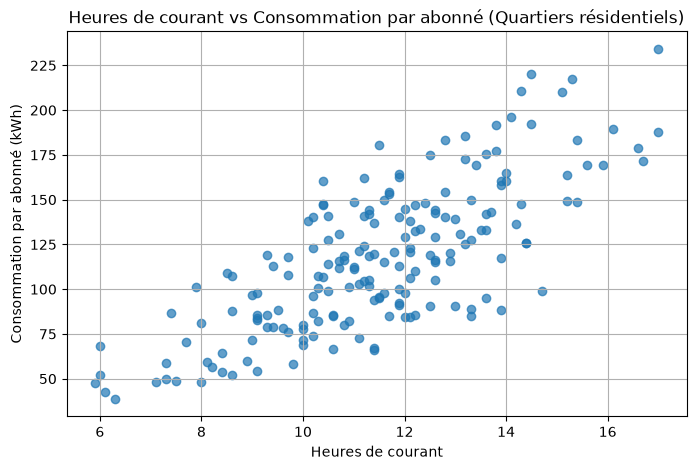

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [14]:
import matplotlib.pyplot as plt

df_res = df_propre.query("type == 'Résidentiel'").assign(
    conso_abonne=lambda d: d['kwh'] / d['abonnes']
)

plt.figure(figsize=(8, 5))
plt.scatter(df_res['heures_courant'], df_res['conso_abonne'], alpha=0.7)
plt.title("Heures de courant vs Consommation par abonné (Quartiers résidentiels)")
plt.xlabel("Heures de courant")
plt.ylabel("Consommation par abonné (kWh)")
plt.grid(True)
plt.show()

corr_courant = df_res['conso_abonne'].corr(df_res['heures_courant'])
corr_temp = df_res['conso_abonne'].corr(df_res['temperature_c'])

print(f"Corrélation avec les heures de courant : {corr_courant:.2f}")
print(f"Corrélation avec la température : {corr_temp:.2f}")

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Statistiques des heures de courant par commune :
                Médiane    Q1    Q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


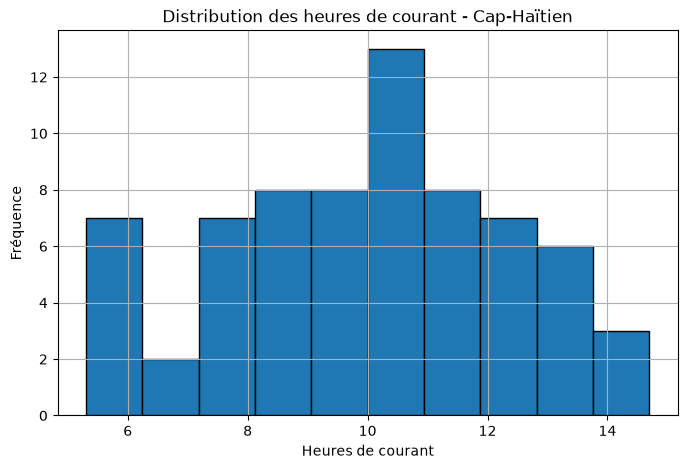


Nombre de relevés en 2025 avec < 8h de courant : 3
Quartiers concernés : ['Delmas 33', 'Carénage', 'Rue 15']


In [15]:
import matplotlib.pyplot as plt

stats_courant = df_propre.groupby('commune')['heures_courant'].quantile([0.5, 0.25, 0.75]).unstack().rename(
    columns={0.5: 'Médiane', 0.25: 'Q1', 0.75: 'Q3'}
)
print("Statistiques des heures de courant par commune :")
print(stats_courant.round(1))

plt.figure(figsize=(8, 5))
df_propre.query("commune == 'Cap-Haïtien'")['heures_courant'].hist(bins=10, edgecolor='black')
plt.title("Distribution des heures de courant - Cap-Haïtien")
plt.xlabel("Heures de courant")
plt.ylabel("Fréquence")
plt.grid(True)
plt.show()

releves_faibles = df_propre.query("mois.str.startswith('2025') and heures_courant < 8")

print(f"\nNombre de relevés en 2025 avec < 8h de courant : {len(releves_faibles)}")
print("Quartiers concernés :", releves_faibles['quartier'].tolist())

**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
top3 = df_propre.nlargest(3, 'kwh')[['mois', 'quartier', 'type', 'kwh']]
print(top3)

       mois      quartier        type       kwh
87  2025-07     Delmas 33  Commercial  742780.0
56  2024-11  Centre-ville  Commercial  597730.0
88  2025-09     Delmas 33  Commercial  591420.0


**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

La consommation suit nettement les heures de courant, affichant une forte corrélation positive de 0,76, tandis que la température n'affiche qu'une corrélation faible et négative de -0,15. Toutefois, il est essentiel de rappeler qu'une corrélation statistique ne permet pas de conclure à une relation de cause à effet directe entre ces variables. D'autres facteurs contextuels ou non mesurés pourraient en effet intervenir sans qu'il y ait de causalité mécanique.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.